# Bài 2: GoogLeNet trên VinaFood21

Huấn luyện GoogLeNet rút gọn với các Inception block; optimizer Adam.

In [ ]:
from pathlib import Path
import os
import sys
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

CODE_DIR = Path(f"*path chứa source code*")
DATA_ROOT = Path("*path chứa dữ liệu VinaFood21*")
OUTPUT_DIR = Path(f"*path chứa output*")

if not (CODE_DIR / "train.py").is_file():
    raise FileNotFoundError(f"Không tìm thấy train.py tại {CODE_DIR}")
if not (DATA_ROOT / "train").is_dir() or not (DATA_ROOT / "test").is_dir():
    raise FileNotFoundError(
        f"DATA_ROOT phải chứa trực tiếp train/ và test/: {DATA_ROOT}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

print("Code:", CODE_DIR)
print("Data:", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Code: /kaggle/input/datasets/vantien113/code-lab2/2/2
Data: /kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21
Output: /kaggle/working/lab2_bai2_outputs


## 1. Kiểm tra môi trường và cấu hình

In [ ]:
RUN_TRAIN = True
RUN_EVALUATION = True

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 20
IMAGE_SIZE = 64

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE, "| Image size:", IMAGE_SIZE)
if DEVICE.type != "cuda":
    print("Chưa bật GPU")

PyTorch: 2.11.0+cu128
Device: cuda
Epochs: 20 | Batch size: 32 | Image size: 64


In [ ]:
def run_module_main(module, arguments):
    """Gọi main() của module."""
    old_argv = sys.argv[:]
    sys.argv = [f"{module.__name__}.py", *map(str, arguments)]
    try:
        module.main()
    finally:
        sys.argv = old_argv

## 2. Huấn luyện

In [ ]:
if RUN_TRAIN:
    import train as train_module
    train_arguments = ['--epochs', '20', '--img_size', '64', '--lr', '0.001', '--data_root', 'VinaFood21', '--batch_size', '32', '--num_workers', '2', '--seed', '42', '--out_dir', 'lab2_bai2_outputs']
    runtime_values = {
        "--data_root": DATA_ROOT,
        "--out_dir": OUTPUT_DIR,
        "--batch_size": BATCH_SIZE,
        "--num_workers": NUM_WORKERS,
        "--seed": SEED,
        "--epochs": EPOCHS,
        "--img_size": IMAGE_SIZE,
    }
    for flag, value in runtime_values.items():
        train_arguments[train_arguments.index(flag) + 1] = str(value)
    run_module_main(train_module, train_arguments)
else:
    print("Bỏ qua train theo cấu hình RUN_TRAIN=False")

Bai2_GoogLeNet | device=cuda | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | train=8537 | val=1507 | params=179,877


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.9091/0.1032 | val 2.8052/0.1314 | macro-F1 0.0532 | 1199.4s  -> saved Bai2_GoogLeNet_best.pt


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.6578/0.1724 | val 2.6407/0.1891 | macro-F1 0.1180 | 88.9s  -> saved Bai2_GoogLeNet_best.pt


...

epoch 18 | train 1.6868/0.4697 | val 1.9621/0.4114 | macro-F1 0.3861 | 89.9s  -> saved Bai2_GoogLeNet_best.pt


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.6555/0.4807 | val 1.9094/0.4161 | macro-F1 0.3836 | 90.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.6144/0.4912 | val 1.8273/0.4466 | macro-F1 0.4097 | 90.2s  -> saved Bai2_GoogLeNet_best.pt
Best epoch 20, validation macro-F1=0.4097: /kaggle/working/lab2_bai2_outputs/Bai2_GoogLeNet_best.pt


## 3. Đánh giá best checkpoint trên tập test

In [5]:
if RUN_EVALUATION:
    import evaluate as evaluate_module
    checkpoint = OUTPUT_DIR / "Bai2_GoogLeNet_best.pt"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    run_module_main(evaluate_module, [
        "--data_root", str(DATA_ROOT), "--ckpt", str(checkpoint),
        "--batch_size", str(BATCH_SIZE), "--num_workers", str(NUM_WORKERS),
    ])
else:
    print("Bỏ qua evaluate theo cấu hình RUN_EVALUATION=False")

Bai2_GoogLeNet | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=20 | test accuracy=0.4181 | precision=0.4074 | recall=0.3930 | macro-F1=0.3902
Đã lưu bảng so sánh với Bài 1: /kaggle/working/lab2_bai2_outputs/Bai2_vs_Bai1.csv


## 4. Toàn bộ lịch sử train theo epoch

In [6]:
history_files = sorted(OUTPUT_DIR.glob("*_history.csv"))
if not history_files:
    raise FileNotFoundError("Không có history CSV; cell train chưa chạy thành công.")

histories = {}
for path in history_files:
    name = path.stem.removesuffix("_history")
    frame = pd.read_csv(path)
    histories[name] = frame
    display(Markdown(f"### Lịch sử epoch — `{name}`"))
    display(frame.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, frame in histories.items():
    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", label=f"{name} train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", linestyle="--",
                 label=f"{name} validation")
    axes[1].plot(frame["epoch"], frame["val_f1_macro"], marker="o", label=name)

axes[0].set(title="Train và validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lịch sử epoch — `Bai2_GoogLeNet`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro,seconds
0,1,2.9091,0.1032,2.8052,0.1314,0.0532,1199.4004
1,2,2.6578,0.1724,2.6407,0.1891,0.1180,88.8864
2,3,2.4513,0.2340,2.4240,0.2581,0.2041,89.2871
3,4,2.3467,0.2658,2.3928,0.2561,0.2113,88.8696
4,5,2.2630,0.2971,2.2537,0.3033,0.2528,88.7561
5,6,2.1896,0.3151,2.2528,0.3099,0.2669,88.9496
6,7,2.1169,0.3452,2.1942,0.3119,0.2713,88.2600
7,8,2.0740,0.3549,2.1549,0.3251,0.2876,88.5660
8,9,2.0134,0.3656,2.2136,0.3212,0.2878,88.1126
9,10,1.9669,0.3858,2.0867,0.3557,0.3304,87.6147


## 5. Hình train/validation loss

### Hình loss đã lưu — `Bai2_GoogLeNet_loss.png`

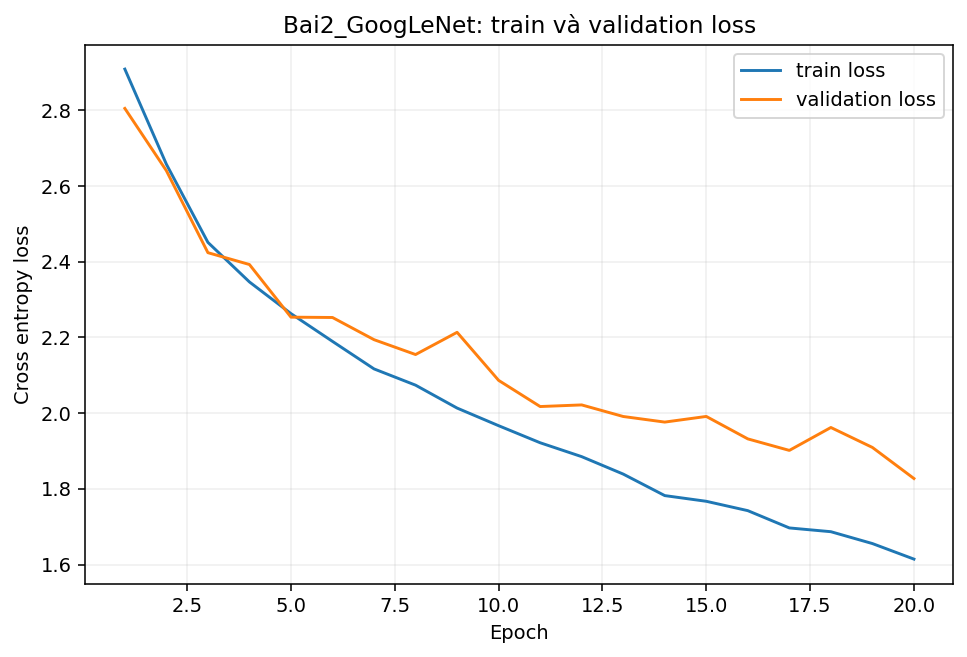

In [7]:
loss_files = sorted(OUTPUT_DIR.glob("*_loss.png"))
for path in loss_files:
    display(Markdown(f"### Hình loss đã lưu — `{path.name}`"))
    display(Image(filename=str(path)))

## 6. Kết quả đánh giá trên test

In [8]:
test_files = sorted(OUTPUT_DIR.glob("*_test.json"))
if not test_files:
    raise FileNotFoundError("Không có test JSON; cell evaluate chưa chạy thành công.")

summaries = []
for path in test_files:
    with path.open(encoding="utf-8") as stream:
        payload = json.load(stream)
    row = payload["summary"].copy()
    row["result_file"] = path.name
    summaries.append(row)

summary_frame = pd.DataFrame(summaries)
preferred = [
    "model", "best_val_epoch", "best_val_f1", "test_loss",
    "accuracy", "precision_macro", "recall_macro", "f1_macro",
    "params", "trainable_params", "seconds_per_epoch", "result_file",
]
shown = [column for column in preferred if column in summary_frame.columns]
display(summary_frame[shown].round(4))

winner = summary_frame.loc[summary_frame["f1_macro"].astype(float).idxmax()]
display(Markdown(
    f"**Mô hình tốt nhất trên test:** `{winner['model']}` — "
    f"accuracy = **{float(winner['accuracy']):.4f}**, "
    f"precision-macro = **{float(winner['precision_macro']):.4f}**, "
    f"recall-macro = **{float(winner['recall_macro']):.4f}**, "
    f"macro-F1 = **{float(winner['f1_macro']):.4f}**."
))

,model,best_val_epoch,best_val_f1,test_loss,accuracy,precision_macro,recall_macro,f1_macro,params,seconds_per_epoch,result_file
0,Bai2_GoogLeNet,20,0.4097,1.8904,0.4181,0.4074,0.393,0.3902,179877,144.3737,Bai2_GoogLeNet_test.json


**Mô hình tốt nhất trên test:** `Bai2_GoogLeNet` — accuracy = **0.4181**, precision-macro = **0.4074**, recall-macro = **0.3930**, macro-F1 = **0.3902**.

## 7. Kết quả từng lớp

In [9]:
per_class_files = sorted(OUTPUT_DIR.glob("*_per_class.csv"))
for path in per_class_files:
    frame = pd.read_csv(path).sort_values("f1", ascending=False)
    display(Markdown(f"### Precision/Recall/F1 từng lớp — `{path.stem.removesuffix('_per_class')}`"))
    display(frame.round(4))

### Precision/Recall/F1 từng lớp — `Bai2_GoogLeNet`

,class,precision,recall,f1,support
13,canh-khoai-mo,0.6535,0.7525,0.6995,198
12,canh-kho-qua,0.6516,0.6448,0.6482,290
9,bo-la-lot,0.5490,0.7707,0.6412,458
1,banh-hoi,0.4826,0.5470,0.5127,607
8,bo-kho,0.4296,0.5059,0.4647,338
2,banh-mi-chao,0.4124,0.5052,0.4541,289
3,banh-tet,0.3806,0.5165,0.4382,364
15,goi-ga,0.3824,0.4034,0.3926,290
6,banh-uot,0.3972,0.3589,0.3771,560
19,tau-hu,0.3376,0.3892,0.3616,203


## 8. Confusion matrix

### Confusion matrix — `Bai2_GoogLeNet`

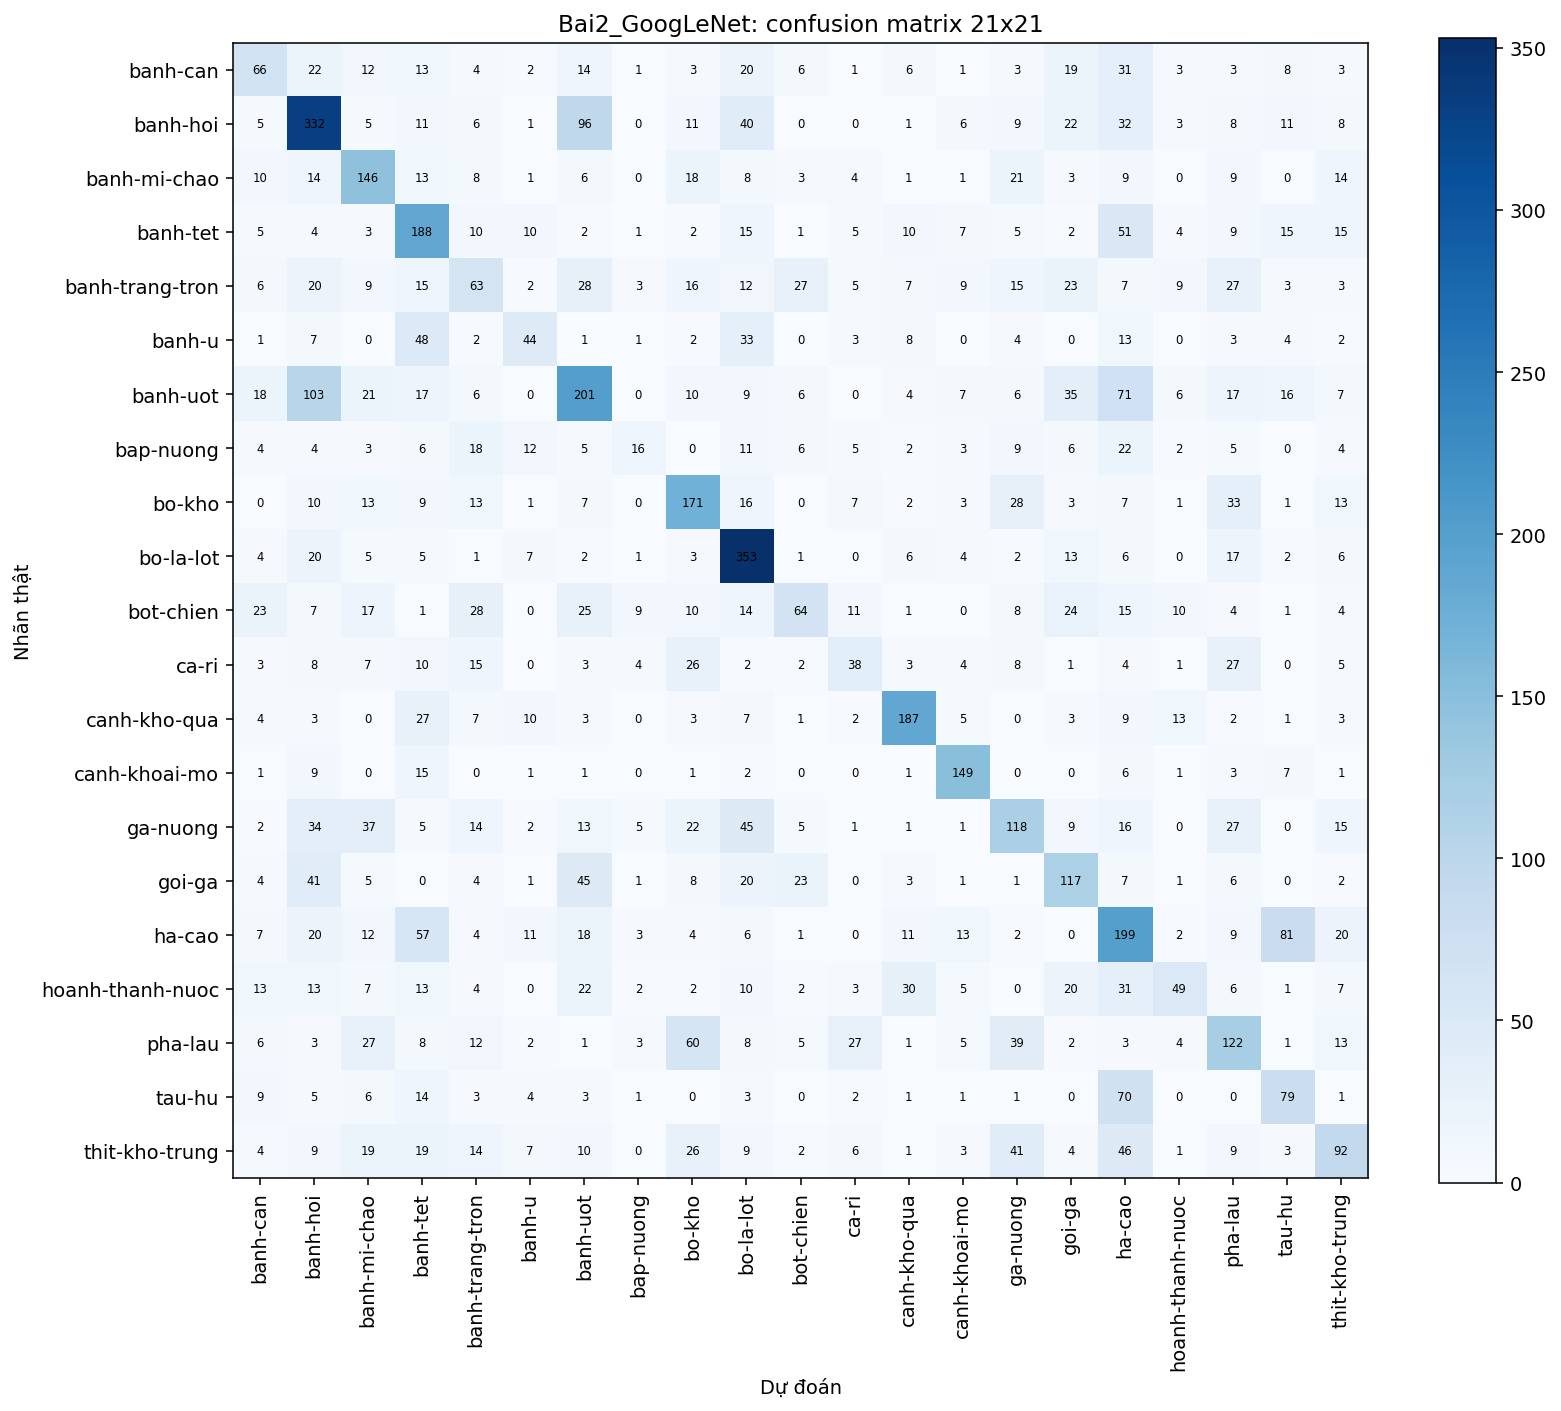

In [10]:
matrix_files = sorted(OUTPUT_DIR.glob("*_confusion_matrix.png"))
for path in matrix_files:
    display(Markdown(f"### Confusion matrix — `{path.stem.removesuffix('_confusion_matrix')}`"))
    display(Image(filename=str(path)))

## 9. Danh sách artifact

In [11]:
rows = [
    {"file": path.name, "size_MB": round(path.stat().st_size / 1024**2, 3)}
    for path in sorted(OUTPUT_DIR.glob("*")) if path.is_file()
]
display(pd.DataFrame(rows))
print("Tất cả artifact được lưu tại:", OUTPUT_DIR)

,file,size_MB
0,Bai2_GoogLeNet_best.pt,0.702
1,Bai2_GoogLeNet_confusion_matrix.png,0.178
2,Bai2_GoogLeNet_history.csv,0.002
3,Bai2_GoogLeNet_loss.png,0.058
4,Bai2_GoogLeNet_per_class.csv,0.001
5,Bai2_GoogLeNet_test.json,0.008
6,Bai2_vs_Bai1.csv,0.000


Tất cả artifact được lưu tại: /kaggle/working/lab2_bai2_outputs


## Kết luận

- Checkpoint được lựa chọn bằng **macro-F1 trên validation**, không dùng test để chọn epoch.
- Các chỉ số test gồm accuracy, precision-macro, recall-macro và macro-F1.